# 🧹 Notebook 02: Text Preprocessing & Train/Val/Test Split
## AI-Generated Text Detection Project

**Goal:** Clean the text, create a stratified train/validation/test split, and save the preprocessed data for use in modeling notebooks (03–05).

**Pipeline Position:** Step 2 of 7 (Data Exploration → **Preprocessing** → Classical Models → LSTM → DistilBERT → Evaluation → Explainability & Ethics)

---

### 🎯 What this notebook does:
1. Loads the cleaned dataset from Notebook 01
2. Cleans text (lowercase, remove URLs, normalize whitespace, remove special chars)
3. Creates two preprocessing variants:
   - **Light cleaning** — for transformers (DistilBERT) which need original casing
   - **Heavy cleaning** — for classical models (TF-IDF, LSTM) with stopword removal + lemmatization
4. Stratified train/val/test split (70/15/15) — preserves class balance AND domain distribution
5. Saves all splits to Drive

**Author:** [Your Name]  
**Date:** 2026

## 📦 Step 1: Install & Import

Same imports as Notebook 01, plus scikit-learn for the train/test split.

In [ ]:
!pip install -q nltk scikit-learn
print("✅ Packages installed")

✅ Packages installed


In [ ]:
import os
import re
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split

# Download NLTK resources
for resource in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(resource, quiet=True)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)
warnings.filterwarnings('ignore')

print("✅ Imports complete")
print(f"✅ Random seed: {SEED}")

✅ Imports complete
✅ Random seed: 42


## 💾 Step 2: Mount Drive & Load Notebook 01 Output

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_PATH = '/content/drive/MyDrive/ai-text-detection'
DATA_PATH = f'{PROJECT_PATH}/data'

# Load the dataset created in Notebook 01
input_file = f'{DATA_PATH}/hc3_processed.csv'

if not os.path.exists(input_file):
    raise FileNotFoundError(f"❌ Cannot find {input_file}. Please run Notebook 01 first!")

df = pd.read_csv(input_file)
print(f"✅ Loaded dataset: {df.shape}")
print(f"📊 Columns: {list(df.columns)}")
df.head(2)

Mounted at /content/drive
✅ Loaded dataset: (85431, 8)
📊 Columns: ['text', 'label', 'label_name', 'domain', 'char_count', 'word_count', 'avg_word_length', 'sentence_count']


,text,label,label_name,domain,char_count,word_count,avg_word_length,sentence_count
0,Eggs shrink as they develop . Even if they 're...,0,Human,reddit_eli5,810,166,4.879518,9
1,"1 . People think insects are gross , and we do...",0,Human,reddit_eli5,455,98,4.642857,6


## 🧹 Step 3: Quality Filtering

Before cleaning, we remove problematic samples that would hurt modeling:
- Empty or null text
- Texts that are too short (< 20 words) — too noisy to classify reliably  
- Texts that are too long (> 1000 words) — outliers, will be truncated by BERT anyway
- Duplicate texts

📝 **For your report:** Document HOW MANY samples you removed and WHY.

In [ ]:
initial_count = len(df)
print(f"📊 Starting samples: {initial_count:,}")

# 1. Remove null/empty
df = df.dropna(subset=['text'])
df = df[df['text'].str.strip() != '']
print(f"  After removing null/empty: {len(df):,}  (-{initial_count - len(df):,})")

prev = len(df)
# 2. Remove too short (< 20 words)
df = df[df['word_count'] >= 20]
print(f"  After removing texts < 20 words: {len(df):,}  (-{prev - len(df):,})")

prev = len(df)
# 3. Remove too long (> 1000 words) — outliers
df = df[df['word_count'] <= 1000]
print(f"  After removing texts > 1000 words: {len(df):,}  (-{prev - len(df):,})")

prev = len(df)
# 4. Remove duplicates
df = df.drop_duplicates(subset='text').reset_index(drop=True)
print(f"  After removing duplicates: {len(df):,}  (-{prev - len(df):,})")

print(f"\n✅ Final clean dataset: {len(df):,} samples")
print(f"📉 Removed: {initial_count - len(df):,} ({(initial_count - len(df))/initial_count*100:.1f}%)")

print(f"\n📊 Class balance after cleaning:")
print(df['label_name'].value_counts())
print(f"\n📊 Domain distribution after cleaning:")
print(df['domain'].value_counts())

📊 Starting samples: 85,431
  After removing null/empty: 85,431  (-0)
  After removing texts < 20 words: 80,667  (-4,764)
  After removing texts > 1000 words: 80,378  (-289)
  After removing duplicates: 74,923  (-5,455)

✅ Final clean dataset: 74,923 samples
📉 Removed: 10,508 (12.3%)

📊 Class balance after cleaning:
label_name
Human      48750
ChatGPT    26173
Name: count, dtype: int64

📊 Domain distribution after cleaning:
domain
reddit_eli5    58186
finance         8264
open_qa         4346
medicine        2519
wiki_csai       1608
Name: count, dtype: int64


## 🧽 Step 4: Define Cleaning Functions

We define **two cleaning levels**:

**Light cleaning** (for transformers like DistilBERT):
- BERT tokenizers handle most cleaning internally
- We only normalize whitespace and remove URLs
- Keep punctuation and casing

**Heavy cleaning** (for classical ML and LSTM):
- Lowercase everything
- Remove URLs, emails, special characters
- Remove stopwords
- Lemmatize words

📝 **For your report:** This dual-cleaning approach is best practice. Mention it in your methodology section.

In [ ]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def light_clean(text):
    """Minimal cleaning for transformer models (DistilBERT)."""
    if not isinstance(text, str):
        return ''
    # Remove URLs
    text = re.sub(r'http\S+|www\.\S+', '', text)
    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)
    # Normalize whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def heavy_clean(text):
    """Heavy cleaning for classical ML / LSTM (TF-IDF, GloVe)."""
    if not isinstance(text, str):
        return ''
    # Lowercase
    text = text.lower()
    # Remove URLs and emails
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'\S+@\S+', '', text)
    # Remove non-alphabetic characters (keep spaces)
    text = re.sub(r'[^a-z\s]', ' ', text)
    # Tokenize
    tokens = text.split()
    # Remove stopwords + lemmatize + filter short tokens
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words and len(t) > 2]
    return ' '.join(tokens)

# Quick demo
sample_text = df['text'].iloc[0][:300]
print("📝 ORIGINAL TEXT (first 300 chars):")
print(sample_text)
print("\n🪶 LIGHT CLEANED:")
print(light_clean(sample_text))
print("\n🔨 HEAVY CLEANED:")
print(heavy_clean(sample_text))

📝 ORIGINAL TEXT (first 300 chars):
Eggs shrink as they develop . Even if they 're not fertile they still shrink as water slowly evaporates . Bird eggs have both a leathery shell ( mostly collagen ) and a hard shell ( mineralized with chalk ) . The leathery shell membrane peels back from the chalky outer shell , and that 's what makes

🪶 LIGHT CLEANED:
Eggs shrink as they develop . Even if they 're not fertile they still shrink as water slowly evaporates . Bird eggs have both a leathery shell ( mostly collagen ) and a hard shell ( mineralized with chalk ) . The leathery shell membrane peels back from the chalky outer shell , and that 's what makes

🔨 HEAVY CLEANED:
egg shrink develop even fertile still shrink water slowly evaporates bird egg leathery shell mostly collagen hard shell mineralized chalk leathery shell membrane peel back chalky outer shell make


## ⚙️ Step 5: Apply Cleaning to All Texts

This may take 1–3 minutes for ~80K samples.

In [ ]:
from time import time

print("🪶 Applying light cleaning...")
t0 = time()
df['text_light'] = df['text'].apply(light_clean)
print(f"  Done in {time() - t0:.1f}s")

print("\n🔨 Applying heavy cleaning (may take 1-2 min)...")
t0 = time()
df['text_heavy'] = df['text'].apply(heavy_clean)
print(f"  Done in {time() - t0:.1f}s")

# Filter out any rows where heavy cleaning produced empty text
before = len(df)
df = df[df['text_heavy'].str.len() > 0].reset_index(drop=True)
print(f"\n  Removed {before - len(df)} rows where heavy cleaning produced empty text")

print(f"\n✅ Cleaning complete. Final dataset: {len(df):,} samples")
df[['text', 'text_light', 'text_heavy']].head(2)

🪶 Applying light cleaning...
  Done in 8.2s

🔨 Applying heavy cleaning (may take 1-2 min)...
  Done in 30.1s

  Removed 4 rows where heavy cleaning produced empty text

✅ Cleaning complete. Final dataset: 74,919 samples


,text,text_light,text_heavy
0,Eggs shrink as they develop . Even if they 're...,Eggs shrink as they develop . Even if they 're...,egg shrink develop even fertile still shrink w...
1,"1 . People think insects are gross , and we do...","1 . People think insects are gross , and we do...",people think insect gross want eat thing think...


## 📊 Step 6: Validate Cleaning Quality

Quick visualization to confirm cleaning didn't destroy too much information.

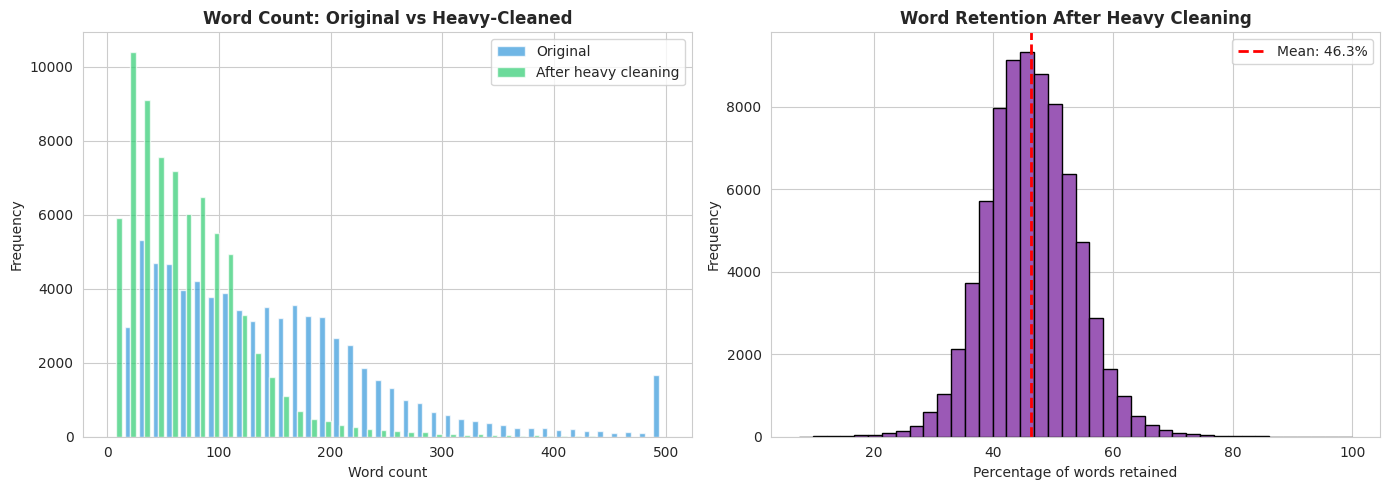


📊 Mean word retention: 46.3%
📊 Min retention: 7.5%
   (Roughly 50% retention is expected after stopword removal — that's healthy)


In [ ]:
# Compute word counts before/after
df['wc_original'] = df['text'].str.split().str.len()
df['wc_heavy'] = df['text_heavy'].str.split().str.len()
df['retention_pct'] = (df['wc_heavy'] / df['wc_original']) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Word count comparison
axes[0].hist([df['wc_original'].clip(upper=500), df['wc_heavy'].clip(upper=500)],
             bins=40, label=['Original', 'After heavy cleaning'],
             color=['#3498db', '#2ecc71'], alpha=0.7)
axes[0].set_title('Word Count: Original vs Heavy-Cleaned', fontweight='bold')
axes[0].set_xlabel('Word count')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Retention percentage
axes[1].hist(df['retention_pct'].clip(upper=100), bins=40, color='#9b59b6', edgecolor='black')
axes[1].axvline(df['retention_pct'].mean(), color='red', linestyle='--', linewidth=2,
                label=f'Mean: {df["retention_pct"].mean():.1f}%')
axes[1].set_title('Word Retention After Heavy Cleaning', fontweight='bold')
axes[1].set_xlabel('Percentage of words retained')
axes[1].set_ylabel('Frequency')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{DATA_PATH}/preprocessing_quality.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n📊 Mean word retention: {df['retention_pct'].mean():.1f}%")
print(f"📊 Min retention: {df['retention_pct'].min():.1f}%")
print("   (Roughly 50% retention is expected after stopword removal — that's healthy)")

## ✂️ Step 7: Stratified Train/Validation/Test Split

Split: **70% train / 15% validation / 15% test**

We use **stratified splitting** by combining label + domain so:
- Class balance (Human/AI) is preserved in every split
- Domain distribution is preserved in every split
- Test set is a fair representation of the full dataset

📝 **For your report (Step 7 of rubric):** This is the proper way to evaluate. Mention stratification explicitly.

In [ ]:
# Combine label + domain for joint stratification
df['stratify_key'] = df['label'].astype(str) + '_' + df['domain']

# First split: train (70%) vs temp (30%)
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=SEED,
    stratify=df['stratify_key']
)

# Second split: temp -> val (15%) + test (15%)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED,
    stratify=temp_df['stratify_key']
)

# Reset indices
train_df = train_df.reset_index(drop=True).drop(columns='stratify_key')
val_df = val_df.reset_index(drop=True).drop(columns='stratify_key')
test_df = test_df.reset_index(drop=True).drop(columns='stratify_key')

print("📊 Split sizes:")
print(f"  Train: {len(train_df):,} ({len(train_df)/len(df)*100:.1f}%)")
print(f"  Val:   {len(val_df):,} ({len(val_df)/len(df)*100:.1f}%)")
print(f"  Test:  {len(test_df):,} ({len(test_df)/len(df)*100:.1f}%)")
print(f"  Total: {len(train_df) + len(val_df) + len(test_df):,}")

📊 Split sizes:
  Train: 52,443 (70.0%)
  Val:   11,238 (15.0%)
  Test:  11,238 (15.0%)
  Total: 74,919


## ✅ Step 8: Verify Split Quality

Confirm the splits preserve both class balance and domain distribution.

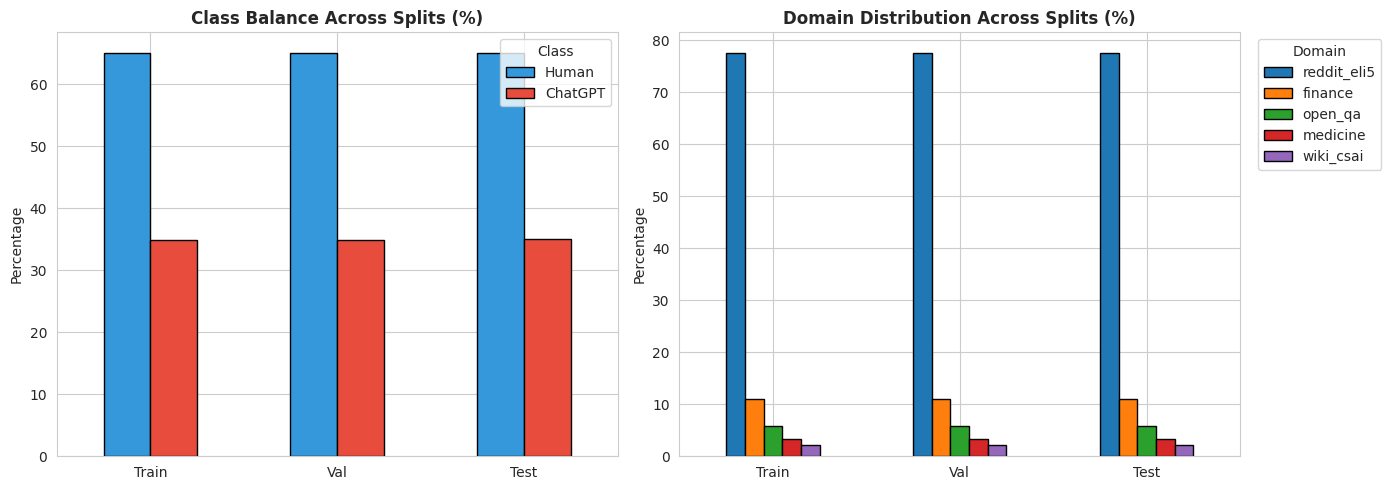


✅ All splits have similar class and domain distributions — stratification worked!


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Class distribution per split
splits_label = pd.DataFrame({
    'Train': train_df['label_name'].value_counts(normalize=True) * 100,
    'Val':   val_df['label_name'].value_counts(normalize=True) * 100,
    'Test':  test_df['label_name'].value_counts(normalize=True) * 100,
}).T
splits_label.plot(kind='bar', ax=axes[0], color=['#3498db', '#e74c3c'], edgecolor='black')
axes[0].set_title('Class Balance Across Splits (%)', fontweight='bold')
axes[0].set_ylabel('Percentage')
axes[0].set_xticklabels(['Train', 'Val', 'Test'], rotation=0)
axes[0].legend(title='Class')

# Domain distribution per split
splits_domain = pd.DataFrame({
    'Train': train_df['domain'].value_counts(normalize=True) * 100,
    'Val':   val_df['domain'].value_counts(normalize=True) * 100,
    'Test':  test_df['domain'].value_counts(normalize=True) * 100,
}).T
splits_domain.plot(kind='bar', ax=axes[1], edgecolor='black')
axes[1].set_title('Domain Distribution Across Splits (%)', fontweight='bold')
axes[1].set_ylabel('Percentage')
axes[1].set_xticklabels(['Train', 'Val', 'Test'], rotation=0)
axes[1].legend(title='Domain', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.savefig(f'{DATA_PATH}/split_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ All splits have similar class and domain distributions — stratification worked!")

## 💾 Step 9: Save Splits to Drive

We save 3 CSV files that all subsequent notebooks (03–05) will load.

In [ ]:
# Drop the helper retention/wc columns to keep files clean
drop_cols = ['wc_original', 'wc_heavy', 'retention_pct']
for d in [train_df, val_df, test_df]:
    d.drop(columns=[c for c in drop_cols if c in d.columns], inplace=True)

# Save
train_df.to_csv(f'{DATA_PATH}/train.csv', index=False)
val_df.to_csv(f'{DATA_PATH}/val.csv', index=False)
test_df.to_csv(f'{DATA_PATH}/test.csv', index=False)

print("✅ Saved splits to Drive:")
for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    fp = f'{DATA_PATH}/{name}.csv'
    print(f"  📄 {fp}  ({len(d):,} rows, {os.path.getsize(fp)/1024**2:.1f} MB)")

✅ Saved splits to Drive:
  📄 /content/drive/MyDrive/ai-text-detection/data/train.csv  (52,443 rows, 109.0 MB)
  📄 /content/drive/MyDrive/ai-text-detection/data/val.csv  (11,238 rows, 23.4 MB)
  📄 /content/drive/MyDrive/ai-text-detection/data/test.csv  (11,238 rows, 23.4 MB)


## 📋 Notebook 02 Summary

### What we accomplished:
1. ✅ Loaded ~85K samples from Notebook 01
2. ✅ Applied quality filtering (length, duplicates, null) — documented removal counts
3. ✅ Created two cleaned versions:
   - `text_light` for DistilBERT (preserves casing, punctuation)
   - `text_heavy` for classical models / LSTM (lowercased, lemmatized, no stopwords)
4. ✅ Stratified 70/15/15 split — preserved class AND domain balance
5. ✅ Saved train.csv, val.csv, test.csv to Drive

### Files Generated:
- `data/train.csv` — Training data (~70%)
- `data/val.csv` — Validation data (~15%)
- `data/test.csv` — Test data (~15%)
- `data/preprocessing_quality.png` — Cleaning impact visualization
- `data/split_distribution.png` — Split balance verification

### 📝 Key Points for Your Report:
- Justify the 70/15/15 split (standard practice, balances training data with reliable evaluation)
- Explain dual-cleaning strategy (transformers vs classical models)
- Document quality filtering numbers (removed X samples for reasons Y)
- Mention stratification by both label AND domain

### ➡️ Next Step:
**Notebook 03 — Classical Models (TF-IDF + Logistic Regression / SVM / Naive Bayes)**

Time estimate: ~30-45 min to run end-to-end.